In [1]:
%pip install -q ultralytics==8.4.174

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 2.6 MB/s eta 0:00:00


In [2]:
from pathlib import Path
from datetime import datetime
import hashlib
import json
import math
import shutil
import zipfile

import torch
import ultralytics
import yaml
import matplotlib.pyplot as plt

from PIL import Image
from matplotlib.patches import Rectangle
from ultralytics import YOLO
from google.colab import files

DATASET = Path("/content/SafraCerta_deteccao")
DATA_YAML = DATASET / "data.yaml"
ZIP_NAME = "SafraCerta_dataset_deteccao_58.zip"

assert torch.cuda.is_available(), (
    "Ative a GPU em Ambiente de execução → "
    "Alterar tipo de ambiente de execução → T4 GPU."
)

print("GPU:", torch.cuda.get_device_name(0))
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: Tesla T4
Ultralytics: 8.4.174
PyTorch: 2.11.0+cu130


In [3]:
ZIP_PATH = Path("/content") / ZIP_NAME

if ZIP_PATH.is_file():
    print("ZIP já disponível:", ZIP_PATH.name)

elif (DATASET / "manifesto.json").is_file():
    print("Dataset já extraído. Pode seguir para a próxima célula.")

else:
    uploaded = files.upload()

    assert ZIP_NAME in uploaded, (
        f"Selecione o arquivo com o nome exato: {ZIP_NAME}"
    )

    ZIP_PATH.write_bytes(uploaded[ZIP_NAME])
    del uploaded

    print("Upload concluído:", ZIP_PATH.name)

Saving SafraCerta_dataset_deteccao_58.zip to SafraCerta_dataset_deteccao_58.zip
Upload concluído: SafraCerta_dataset_deteccao_58.zip


In [4]:
if (DATASET / "manifesto.json").is_file():
    print("Dataset já extraído.")

else:
    assert ZIP_PATH.is_file(), "Execute primeiro a célula 3."

    with zipfile.ZipFile(ZIP_PATH) as z:
        for entry in z.infolist():
            parts = Path(entry.filename).parts

            assert parts and parts[0] == DATASET.name
            assert ".." not in parts
            assert not Path(entry.filename).is_absolute()

        z.extractall("/content")

    print("Dataset extraído com sucesso!")

assert DATA_YAML.is_file(), "O data.yaml não foi encontrado."

config = yaml.safe_load(DATA_YAML.read_text())
config["path"] = str(DATASET)

DATA_YAML.write_text(
    yaml.safe_dump(config, allow_unicode=True, sort_keys=False)
)

print(DATA_YAML.read_text())

Dataset extraído com sucesso!
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: folha
path: /content/SafraCerta_deteccao



In [5]:
manifest = json.loads((DATASET / "manifesto.json").read_text())
seen = set()

expected_counts = {
    "train": 38,
    "val": 10,
    "test": 10
}

for split, expected in expected_counts.items():
    images = sorted((DATASET / "images" / split).glob("*.jpg"))
    labels = sorted((DATASET / "labels" / split).glob("*.txt"))

    assert len(images) == len(labels) == expected, (
        f"{split}: encontrei {len(images)} imagens "
        f"e {len(labels)} anotações; esperava {expected}."
    )

    assert {p.stem for p in images} == {p.stem for p in labels}, (
        f"Há imagens sem anotação ou anotações sem imagem em {split}."
    )

    for image in images:
        with Image.open(image) as im:
            im.verify()

        digest = hashlib.sha256(image.read_bytes()).hexdigest()

        assert digest not in seen, "Imagem duplicada no conjunto."
        seen.add(digest)

        label = DATASET / "labels" / split / (image.stem + ".txt")
        rows = label.read_text().strip().splitlines()

        assert len(rows) == 1, (
            f"Quantidade inesperada de caixas: {label.name}"
        )

        values = rows[0].split()
        assert len(values) == 5 and values[0] == "0"

        x, y, w, h = map(float, values[1:])

        assert all(math.isfinite(v) for v in [x, y, w, h])
        assert 0 < w <= 1 and 0 < h <= 1
        assert x - w / 2 >= -1e-6
        assert y - h / 2 >= -1e-6
        assert x + w / 2 <= 1 + 1e-6
        assert y + h / 2 <= 1 + 1e-6

    print(f"{split}: {expected} imagens e anotações conferidas.")

assert len(manifest) == 58

for record in manifest:
    image = DATASET / record["imagem"]

    assert hashlib.sha256(image.read_bytes()).hexdigest() == (
        record["sha256"]
    ), f"Imagem diferente do manifesto: {image.name}"

print("\nConferência concluída: 58 imagens.")

train: 38 imagens e anotações conferidas.
val: 10 imagens e anotações conferidas.
test: 10 imagens e anotações conferidas.

Conferência concluída: 58 imagens.


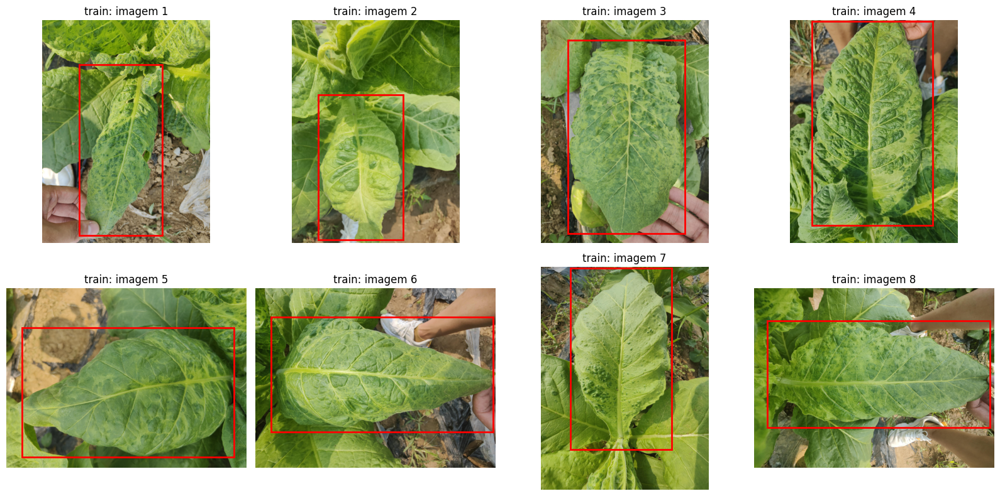

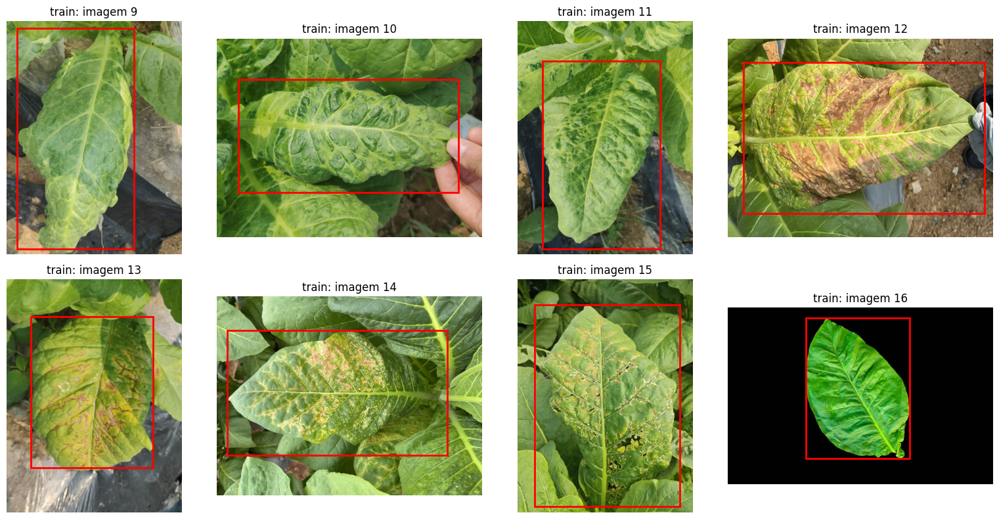

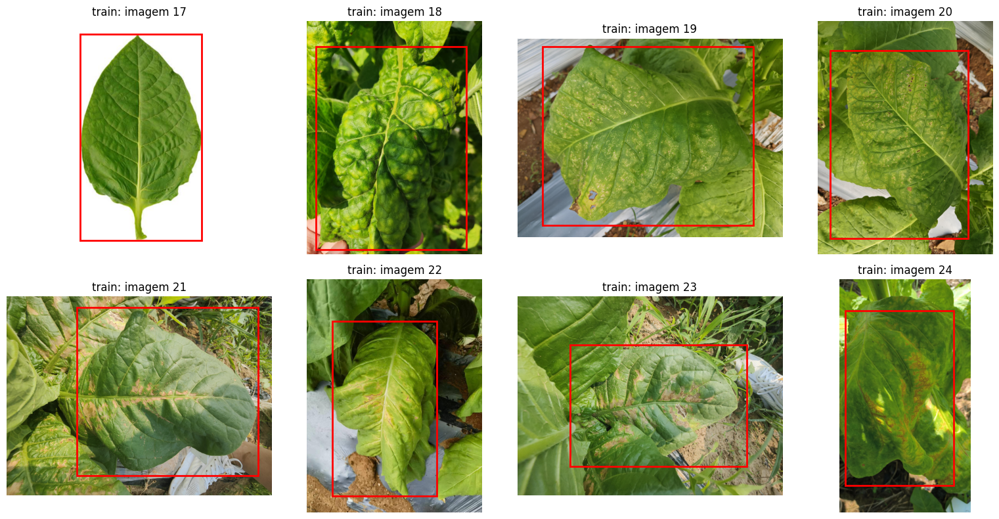

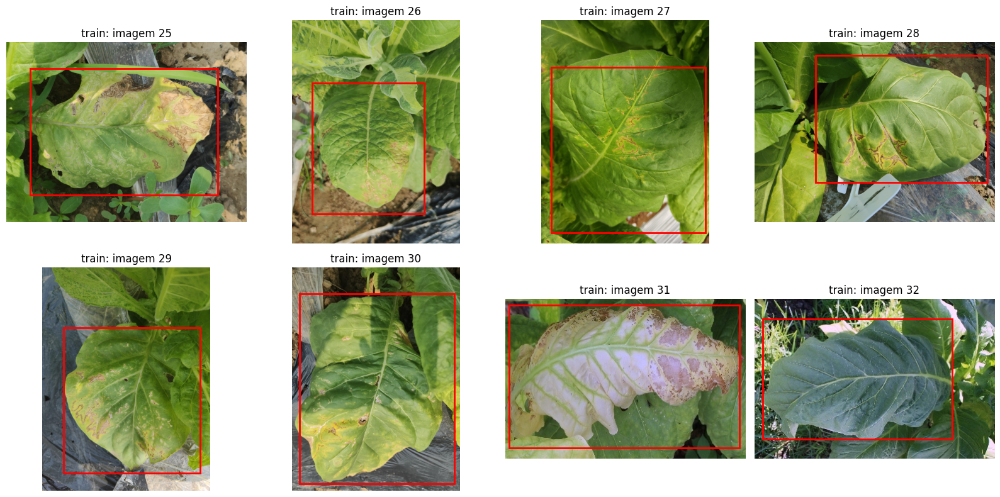

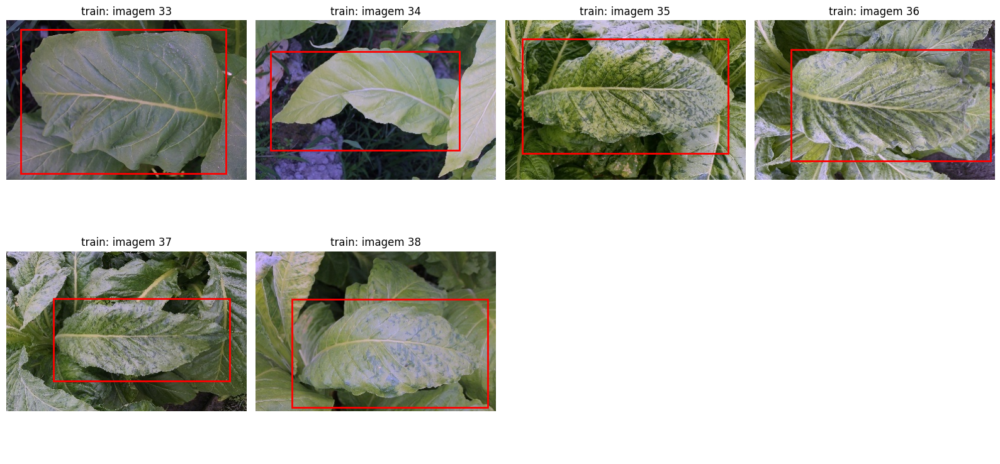

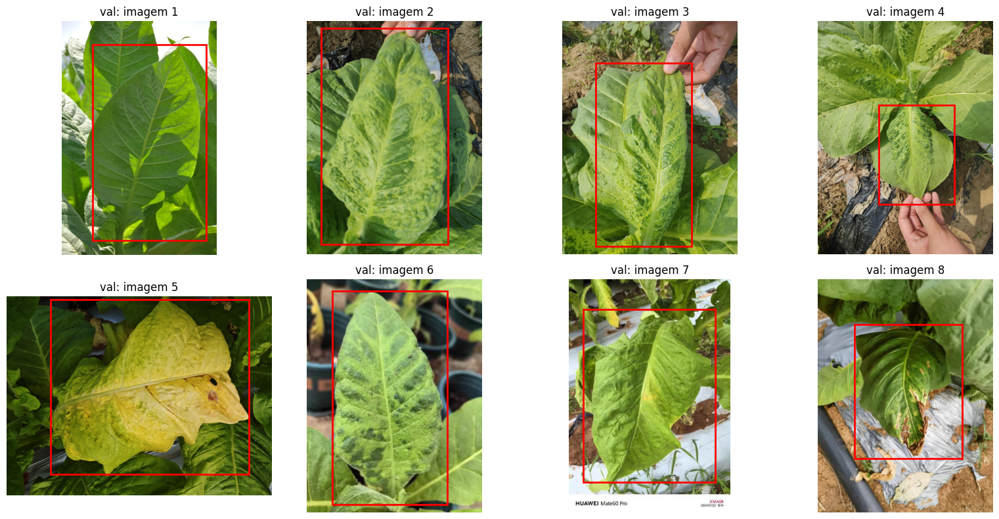

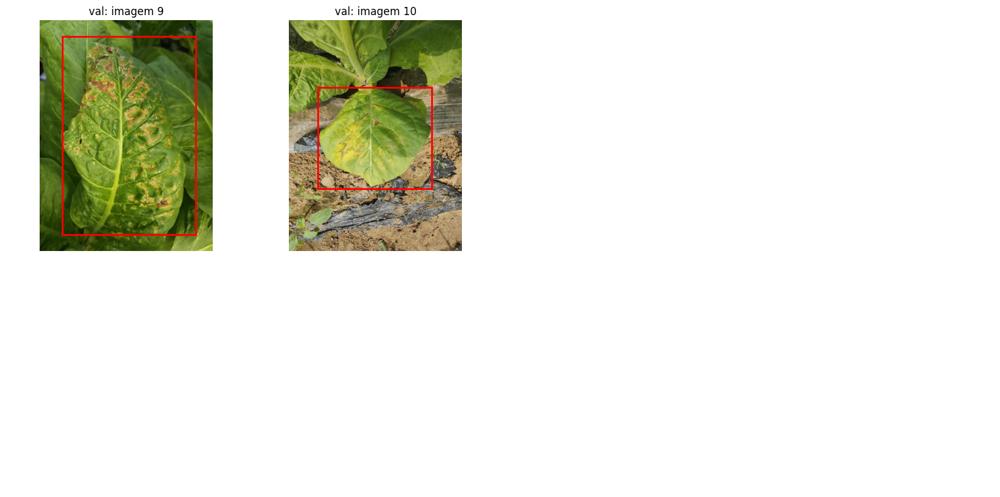

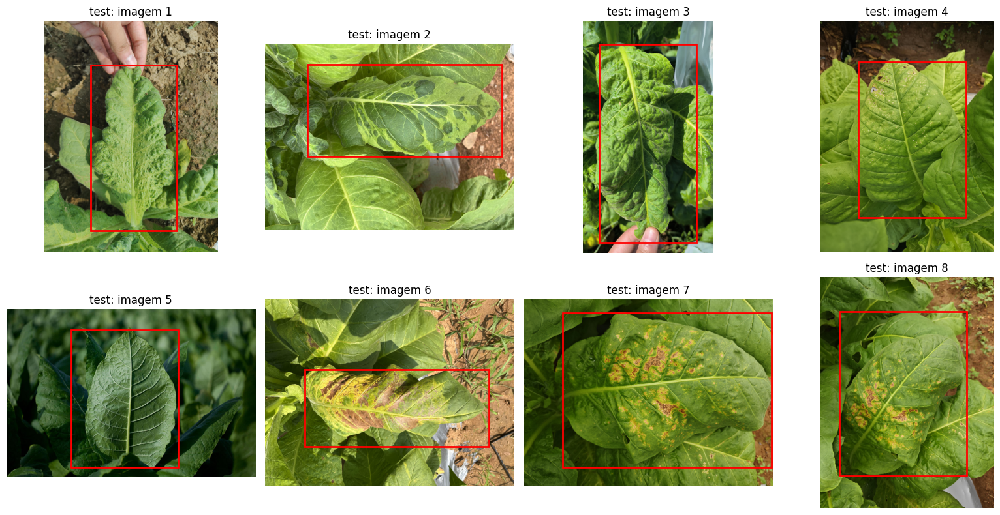

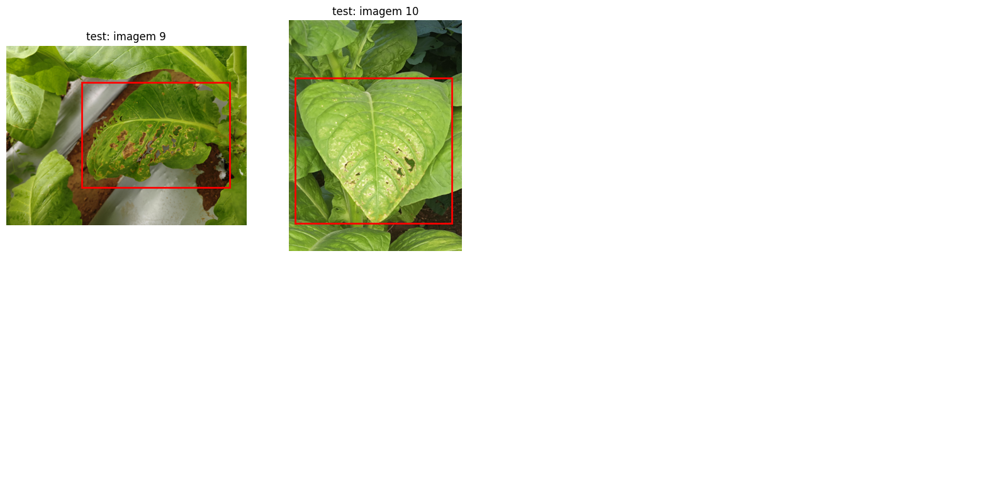

In [6]:
for split in ["train", "val", "test"]:
    images = sorted((DATASET / "images" / split).glob("*.jpg"))

    for start in range(0, len(images), 8):
        fig, axes = plt.subplots(2, 4, figsize=(16, 8))

        for ax in axes.flat:
            ax.axis("off")

        batch = images[start:start + 8]

        for index, (ax, image) in enumerate(
            zip(axes.flat, batch),
            start=start + 1
        ):
            with Image.open(image) as original:
                im = original.convert("RGB")

            iw, ih = im.size
            label = DATASET / "labels" / split / (image.stem + ".txt")

            _, x, y, w, h = map(float, label.read_text().split())

            ax.imshow(im)

            ax.add_patch(
                Rectangle(
                    ((x - w / 2) * iw, (y - h / 2) * ih),
                    w * iw,
                    h * ih,
                    fill=False,
                    edgecolor="red",
                    linewidth=2
                )
            )

            ax.set_title(f"{split}: imagem {index}")

        plt.tight_layout()
        plt.show()

In [7]:
RESULTS = Path("/content/SafraCerta_resultados_deteccao")
RESULTS.mkdir(parents=True, exist_ok=True)

RUN_NAME = "treino_folha_" + datetime.now().strftime("%Y%m%d_%H%M%S")

model = YOLO("yolo26n.pt")
assert model.task == "detect"

model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    patience=10,
    device=0,
    workers=2,
    seed=42,
    mosaic=0.0,
    mixup=0.0,
    plots=True,
    save=True,
    project=str(RESULTS),
    name=RUN_NAME,
    exist_ok=False
)

RUN = Path(model.trainer.save_dir)
BEST = RUN / "weights" / "best.pt"

assert BEST.is_file(), (
    "O best.pt não foi encontrado. Confira a saída do treinamento."
)

print("\nTreinamento concluído!")
print("best.pt:", BEST)

New https://pypi.org/project/ultralytics/8.4.175 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/SafraCerta_deteccao/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt,

In [8]:
detector = YOLO(str(BEST))

metrics = detector.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project=str(RUN),
    name="teste_final",
    exist_ok=False
)

summary = {
    "modelo_inicial": "yolo26n.pt",
    "classe": "folha",
    "imagens_treino": 38,
    "imagens_validacao": 10,
    "imagens_teste": 10,
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map),
    "precisao": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "ultralytics": ultralytics.__version__,
    "torch": torch.__version__,
    "limitacao": (
        "Dataset piloto com caixas aproximadas da folha principal; "
        "não há anotação completa de todas as folhas secundárias."
    )
}

(RUN / "metricas_teste.json").write_text(
    json.dumps(summary, indent=2, ensure_ascii=False)
)

print(json.dumps(summary, indent=2, ensure_ascii=False))

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3589.4±710.6 MB/s, size: 925.6 KB)
val: Scanning /content/SafraCerta_deteccao/labels/test... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 1.6Kit/s 0.0s
val: New cache created: /content/SafraCerta_deteccao/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.5it/s 1.4s
                   all         10         10      0.988          1      0.995      0.696
Speed: 9.4ms preprocess, 47.5ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/SafraCerta_resultados_deteccao/treino_folha_20261011_141733/teste_final
{
  "modelo_inicial": "yolo26n.pt",
  "classe": "folha",
  "imagens_treino": 38,
  "imagens_validacao": 10,
  "imagens_teste": 10,
  "mAP50": 0.995,



image 1/10 /content/SafraCerta_deteccao/images/test/roboflow__haungguahuayebing-110-_jpg.rf.a9637d3e182c524faa7d36fa9da945be.jpg: 640x480 1 folha, 13.3ms
image 2/10 /content/SafraCerta_deteccao/images/test/roboflow__haungguahuayebing-247-_jpg.rf.d10ba0e2835c062f504132bafb539584.jpg: 480x640 1 folha, 74.3ms
image 3/10 /content/SafraCerta_deteccao/images/test/roboflow__haungguahuayebing-59-_jpg.rf.b41060a1ea964d8e400342a9872c2d96.jpg: 640x384 1 folha, 72.7ms
image 4/10 /content/SafraCerta_deteccao/images/test/roboflow__malingshuYbingdubing-24-_jpg.rf.75a7b754909023c5c0c61e1d88d7d45f.jpg: 640x480 2 folhas, 17.7ms
image 5/10 /content/SafraCerta_deteccao/images/test/roboflow__tobacco-leaf-1780x1200_webp.rf.569d80243f070d9d83ff616af5a2878e.jpg: 448x640 1 folha, 71.2ms
image 6/10 /content/SafraCerta_deteccao/images/test/roboflow__yehuobing-12-_jpg.rf.34f6b8138ece1677d5b73a8ee2cd2e8c.jpg: 480x640 1 folha, 13.8ms
image 7/10 /content/SafraCerta_deteccao/images/test/roboflow__yehuobing-33-_jpg.r

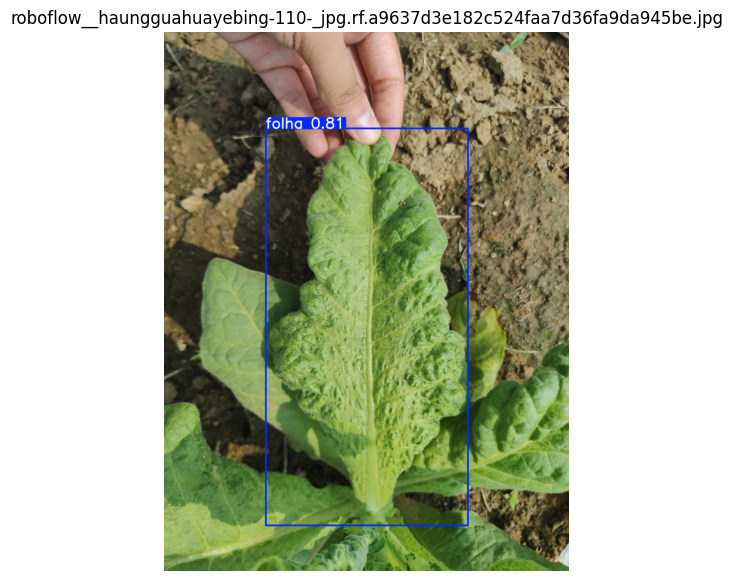

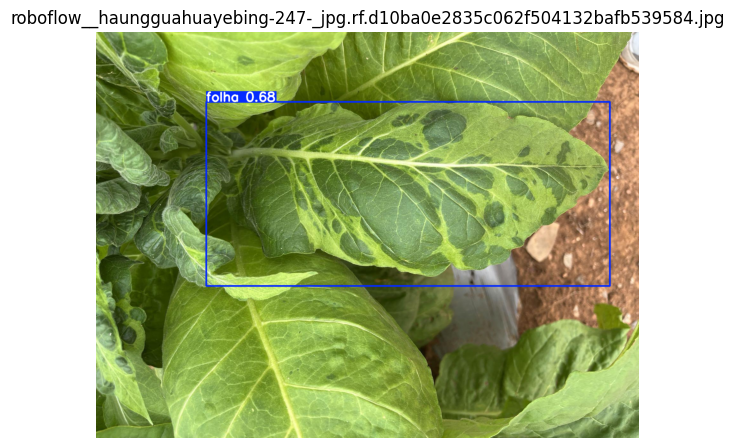

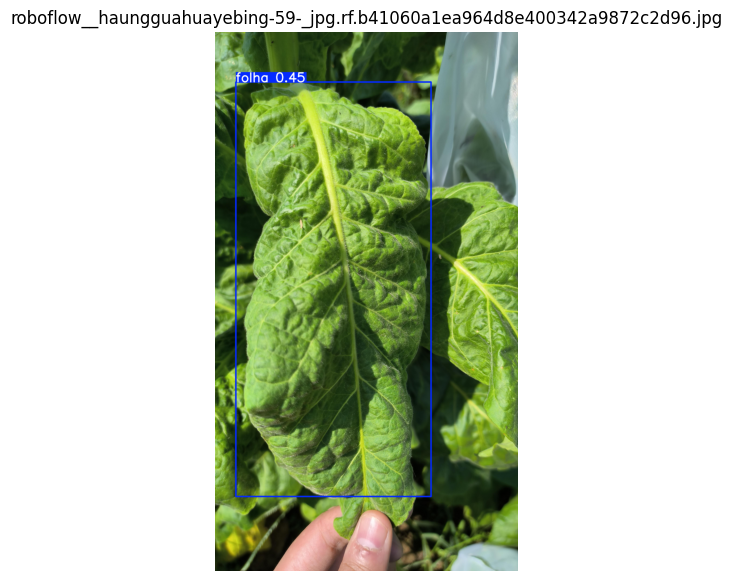

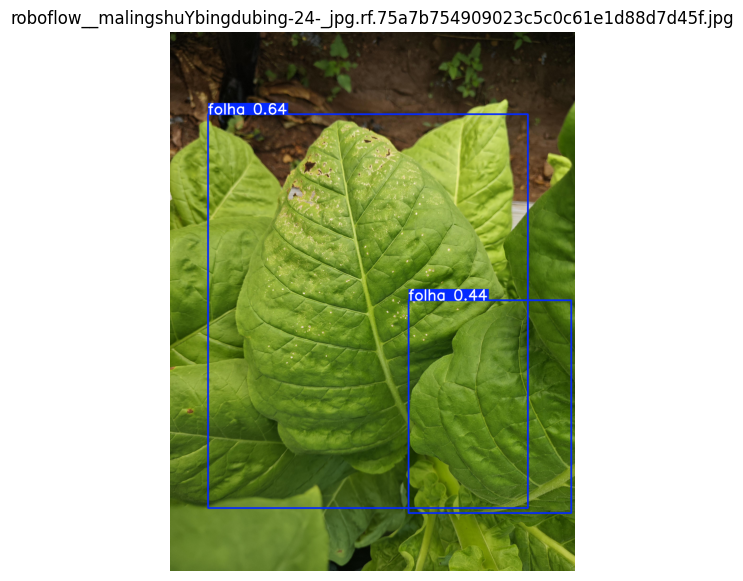

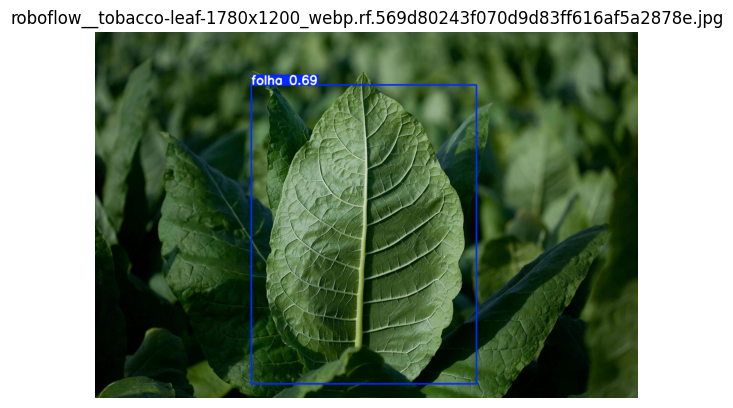

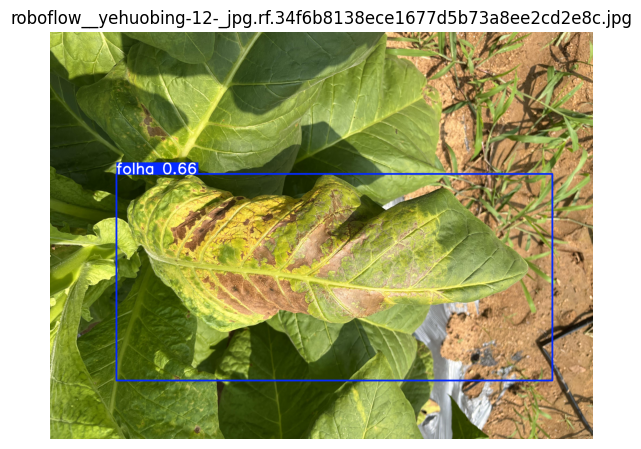

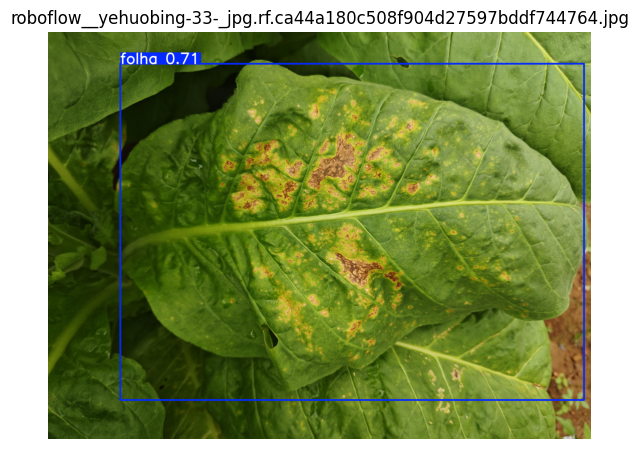

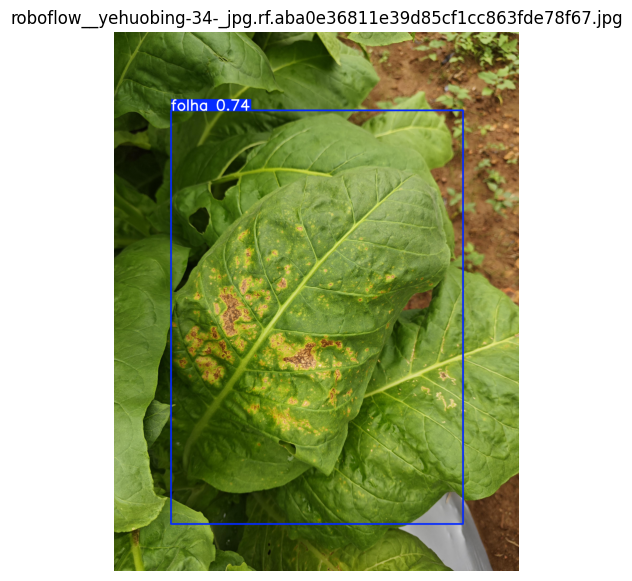

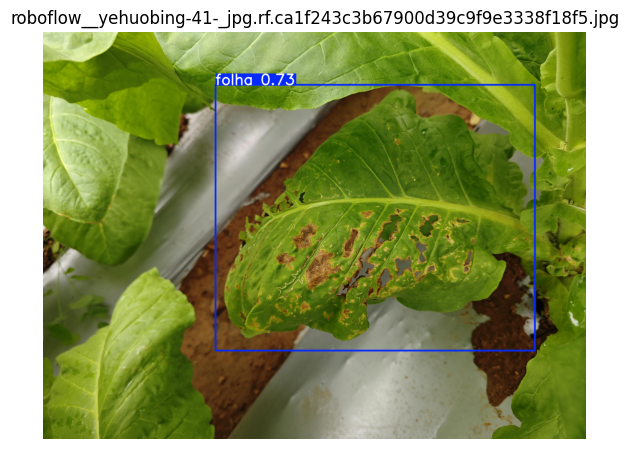

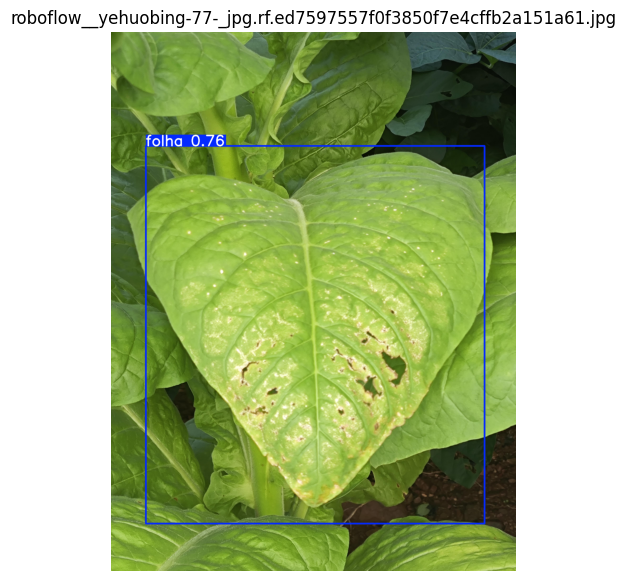

In [9]:
predictions = detector.predict(
    source=str(DATASET / "images" / "test"),
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    save_txt=True,
    save_conf=True,
    project=str(RUN),
    name="previsoes_teste",
    exist_ok=False
)

for result in predictions:
    plt.figure(figsize=(7, 7))
    plt.imshow(result.plot()[..., ::-1])
    plt.title(Path(result.path).name)
    plt.axis("off")
    plt.show()

In [10]:
for name in [
    "data.yaml",
    "manifesto.json",
    "triagem_duplicatas.json",
    "LEIA-ME.txt"
]:
    shutil.copyfile(DATASET / name, RUN / name)

(RUN / "localizacao_best.txt").write_text(
    "weights/best.pt"
)

result_zip = shutil.make_archive(
    str(Path("/content") / f"SafraCerta_deteccao_{RUN.name}"),
    "zip",
    root_dir=str(RUN)
)

print("ZIP gerado:", result_zip)
print("Modelo dentro do ZIP: weights/best.pt")

files.download(result_zip)

ZIP gerado: /content/SafraCerta_deteccao_treino_folha_20261011_141733.zip
Modelo dentro do ZIP: weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
files.download(str(BEST))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>